Outlier Detection

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

data={
    "Students": ["A","B","C","D","E","F","G","H","I","J","K","L","M","O"],
    "Study_Hours":[2,3,4,5,6,5,3,4,5,6,4,5,30,3]
}
df=pd.DataFrame(data)
print("Original Dataset")
display(df)

Original Dataset


,Students,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,6
5,F,5
6,G,3
7,H,4
8,I,5
9,J,6


describe

In [ ]:
df["Study_Hours"].describe()

,Study_Hours
count,14.000000
mean,6.071429
std,6.988609
min,2.000000
25%,3.250000
50%,4.500000
75%,5.000000
max,30.000000


visualize possible outlier

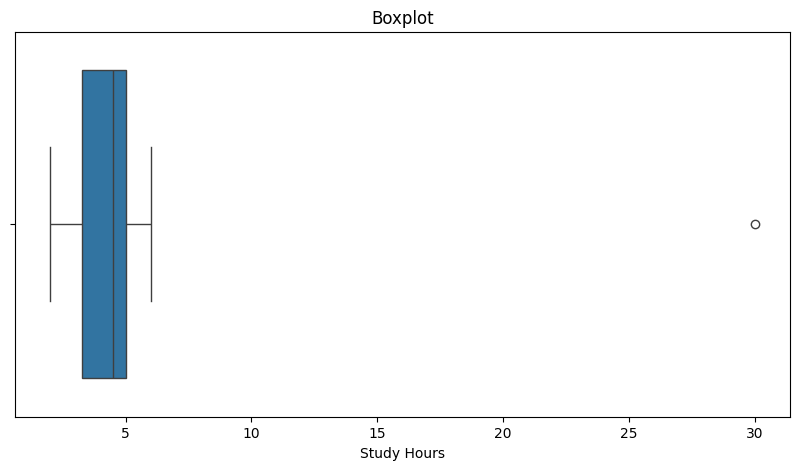

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df,x="Study_Hours")
plt.title("Boxplot")
plt.xlabel("Study Hours")
plt.show()

iqr method

In [ ]:
Q1=df["Study_Hours"].quantile(0.25)
Q3=df["Study_Hours"].quantile(0.75)
print("Q1:",Q1)
print("Q3:",Q3)

Q1: 3.25
Q3: 5.0


calculate boundaries

In [ ]:
lower_bound=Q1-1.5*(Q3-Q1)
upper_bound=Q3+1.5*(Q3-Q1)
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Lower Bound: 0.625
Upper Bound: 7.625


outlier using boundaries


> Add blockquote



In [ ]:
outliers_iqr=df[(df["Study_Hours"]<lower_bound) | (df["Study_Hours"]>upper_bound)]
print("Outliers using IQR Method")
display(outliers_iqr)


Outliers using IQR Method


,Students,Study_Hours
12,M,30


non-outlier data

z score method

In [ ]:
df["Z_Score"]=zscore(df["Study_Hours"])
display(df)

,Students,Study_Hours,Z_Score
0,A,2,-0.604573
1,B,3,-0.456081
2,C,4,-0.307590
3,D,5,-0.159098
4,E,6,-0.010607
5,F,5,-0.159098
6,G,3,-0.456081
7,H,4,-0.307590
8,I,5,-0.159098
9,J,6,-0.010607


In [ ]:
z_outliers=df[(df["Z_Score"]>3) | df(df["Z_Score"]<-3)]
print("Outliers using Z-Score Method")
display(z_outliers)

TypeError: 'DataFrame' object is not callable

treatment of outliers

In [ ]:
df_without_outliers=df[(df["Study_Hours"]>=lower_bound) & (df["Study_Hours"]<=upper_bound)]
display(df_without_outliers)

,Students,Study_Hours,Z_Score
0,A,2,-0.604573
1,B,3,-0.456081
2,C,4,-0.307590
3,D,5,-0.159098
4,E,6,-0.010607
5,F,5,-0.159098
6,G,3,-0.456081
7,H,4,-0.307590
8,I,5,-0.159098
9,J,6,-0.010607


capping

In [ ]:
df_capped=df.copy()
df_capped["Study_Hours"]=df_capped["Study_Hours"].clip(lower=lower_bound,upper=upper_bound)
display(df_capped)

,Students,Study_Hours,Z_Score
0,A,2.000,-0.604573
1,B,3.000,-0.456081
2,C,4.000,-0.307590
3,D,5.000,-0.159098
4,E,6.000,-0.010607
5,F,5.000,-0.159098
6,G,3.000,-0.456081
7,H,4.000,-0.307590
8,I,5.000,-0.159098
9,J,6.000,-0.010607


final visualization

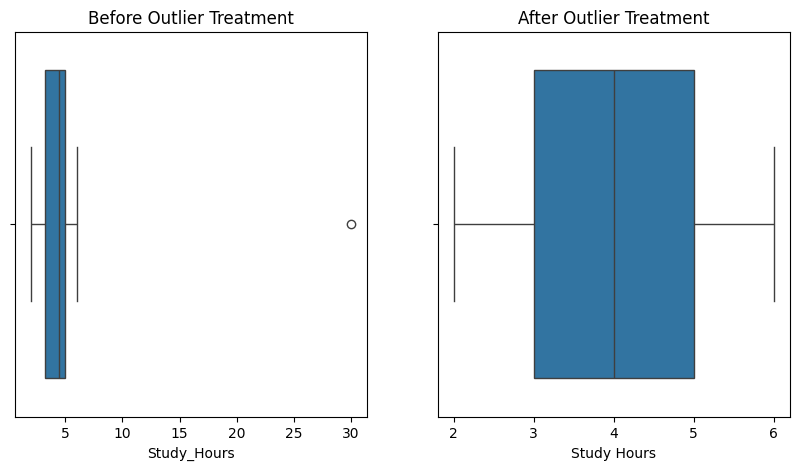

In [ ]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.boxplot(data=df,x="Study_Hours")
plt.title("Before Outlier Treatment")
plt.subplot(1,2,2)
sns.boxplot(data=df_without_outliers,x="Study_Hours")
plt.title("After Outlier Treatment")
plt.xlabel("Study Hours")
plt.show()